# 16 — La combinación que funciona y el camino a un entrenamiento holístico

## Por qué existe este cuaderno

El cuaderno 15 encontró la mejor forma de predecir **con lo que había**: la **combinación SARIMAX +
LightGBM**. El propietario reconoce que predijo bien 2026, un año que no había visto, a corto y mediano
plazo. Pero señala cinco problemas de fondo en **con qué se entrenó** (docs/CONTEXTO.md, 2026-10-05):

1. **EPS:** solo se mide Nueva EPS, como si fuera la única. Falta el estado de todas las EPS.
2. **Clima:** falta el contexto completo: humedad, lluvia, sol, cuánto tiempo lleva haciendo sol, los
   cambios bruscos.
3. **Salud:** no solo IRA. Al menos las 5 enfermedades más comunes, cruzadas con clima, fiestas,
   vacaciones y horario escolar.
4. **Fenómenos:** se marcó la COVID, pero no El Niño y La Niña, terremotos, epidemias.
5. **«Parece que se le dieron las respuestas de 2026».** El periodo es corto y el entrenamiento, demasiado
   específico.

**El proyecto se fue a lo específico y perdió la vista general.** Este cuaderno:
- explica **la combinación**, por qué sus dos partes son compatibles y por qué su respuesta es confiable;
- **mide cada preocupación** con datos, para saber cuánto tiene de razón;
- reúne **todas las fuentes** que se pueden sumar, incluidos el SIVIGILA y el estado de todas las EPS;
- responde **cuánto se le puede dar al modelo antes de sobreajustarlo**, y explica el **método de
  rejilla**;
- propone **un diseño de entrenamiento holístico**, para decidirlo con el propietario.

In [1]:
import sys, pathlib, warnings, json
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks")); sys.path.insert(0, str(RAIZ)); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from matplotlib import pyplot as plt
import pronostico as pr

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]

def tabla(P, vara="calendario"):
    _, U = pr.leer(["control"], exp="e0", vara=vara)
    _, T = pr.metricas(P, U)
    return T[["acierta sube/baja %", "BSS sube %", "BSS pico %", "cob80 %", "MAPE %"]]

---
# 1. La respuesta de hoy: la combinación SARIMAX + LightGBM

## Qué es cada parte, en simple

| | **SARIMAX** | **LightGBM** |
|---|---|---|
| Familia | Serie de tiempo estadística | Ensamble de árboles de decisión con refuerzo (*gradient boosting*) |
| Cómo piensa | «Mañana se parecerá a hoy, corregido por el día de la semana, el calendario y la época del año.» Se **actualiza cada día** con lo que acaba de pasar | Hace cientos de preguntas en cadena («¿es lunes?, ¿es después de festivo?, ¿la semana pasada estuvo alta?…»), y cada árbol corrige los errores del anterior |
| En qué es bueno | **Seguir los cambios de nivel** (los escalones de Nueva EPS) y dar **rangos honestos** | **Combinaciones de factores** que una fórmula lineal no ve, sobre todo en los meses estables |
| En qué falla | Es lineal: no capta interacciones | Se **confía de más** (rangos estrechos) y se adapta lento a un escalón nuevo |

**La combinación** promedia, cuantil a cuantil, las dos distribuciones: la mediana con la mediana, el 10 %
con el 10 %… Así se obtiene una sola predicción con su rango.

## Por qué son compatibles: se equivocan en momentos distintos

Correlación de los errores SARIMAX-LightGBM: 0.85
Días en que uno se equivoca hacia arriba y el otro hacia abajo: 21%


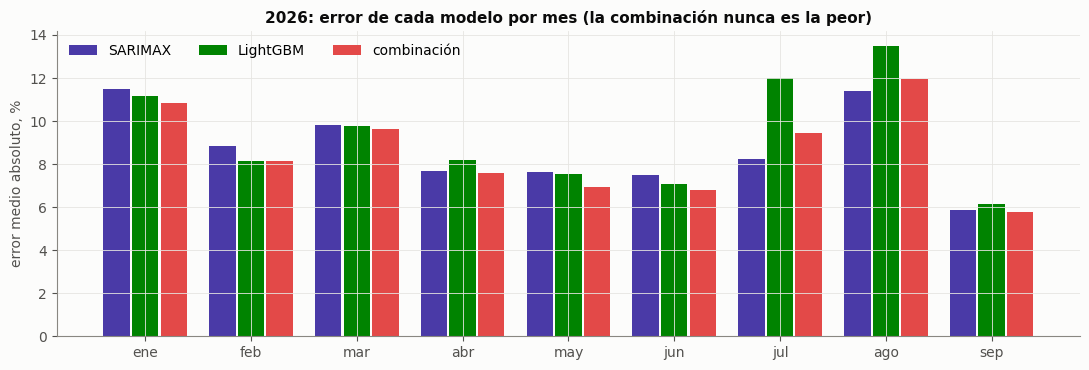

,acierta sube/baja %,BSS sube %,BSS pico %,cob80 %,MAPE %
modelo,,,,,
SARIMAX + LightGBM,69.4,21.1,16.5,80.3,8.9
LightGBM,67.8,15.9,11.4,71.2,9.8
SARIMAX,66.8,18.8,13.3,85.4,9.0


In [2]:
P, _ = pr.leer(["sarimax", "lightgbm", "comb_sarimax_lightgbm"], exp="e1"); P = P[P.origen >= "2025-12-31"].dropna(subset=["real"])
w = P.pivot_table(index=["origen", "h", "fecha"], columns="modelo", values="q50")
real = P.drop_duplicates(["origen", "h"]).set_index(["origen", "h", "fecha"])["real"]
err = np.log(w.div(real, axis=0)) * 100
print(f"Correlación de los errores SARIMAX-LightGBM: {err.sarimax.corr(err.lightgbm):.2f}")
print(f"Días en que uno se equivoca hacia arriba y el otro hacia abajo: {(np.sign(err.sarimax) != np.sign(err.lightgbm)).mean():.0%}")
m = err.abs().reset_index(); m["mes"] = m.fecha.dt.month
porm = m.groupby("mes")[["sarimax", "lightgbm", "comb_sarimax_lightgbm"]].mean()
fig, ax = plt.subplots(figsize=(11, 3.8)); x = np.arange(len(porm))
for j, (c, col, n) in enumerate([("sarimax", VIOLETA, "SARIMAX"), ("lightgbm", VERDE, "LightGBM"), ("comb_sarimax_lightgbm", ROJO, "combinación")]):
    ax.bar(x + (j - 1) * .27, porm[c], width=.25, color=col, label=n)
ax.set_xticks(x, [MESES[i - 1] for i in porm.index]); ax.set_ylabel("error medio absoluto, %")
ax.set_title("2026: error de cada modelo por mes (la combinación nunca es la peor)"); ax.legend(ncol=3); plt.tight_layout(); plt.show()
T = tabla(P); T.index = T.index.map({"sarimax": "SARIMAX", "lightgbm": "LightGBM", "comb_sarimax_lightgbm": "SARIMAX + LightGBM"}); T.round(1)

**Lectura.**

- **Los dos modelos se equivocan parecido (correlación de 0,85), pero no igual.**
  - El 21 % de los días uno queda por encima de lo real y el otro por debajo, y al promediarlos el error se cancela.
  - **LightGBM falla más después de un escalón de Nueva EPS** (julio-agosto, 12-13 %), donde SARIMAX se adapta en días.
  - **SARIMAX falla un poco más en los meses tranquilos.**
- **La combinación nunca es la peor en ningún mes**, y en 2026 es la mejor en casi todo:
  - 69,4 % de acierto;
  - +21,1 % de mejora en la probabilidad;
  - **rango del 80 % cumplido el 80,3 % de las veces**: ni se sobreconfía como LightGBM ni se pasa de prudente como SARIMAX.
- **Por qué son compatibles:** son de familias opuestas. Una fórmula que sigue el nivel día a día y un conjunto de reglas que captan combinaciones. Sus aciertos y sus fallos están en lugares distintos, y es la situación en que combinar pronósticos funciona.

---
# 2. ¿Se le dieron las respuestas de 2026?

Hay que separar dos cosas que suenan igual y no lo son.

**(a) Fuga de datos: no hubo.** Cada predicción de 2026 se hizo con el **origen rodante**:
- el día *o*, el modelo solo conocía el triage y el contexto hasta *o*, y predecía *o+1* a *o+7*;
- cada 7 días se reentrenaba con todo lo anterior.

El modelo nunca vio el día que predecía. Eso está garantizado por cómo está escrito el código
(`notebooks/pronostico.py`).

**(b) Elegir mirando la prueba: sí pasó.** Se probaron unos 20 diseños sobre el mismo 2026:
- los experimentos E0 a E3;
- el jerárquico, con suma y con cópula;
- 42 modelos de LazyPredict;
- 3 árboles afinados;
- 2 combinaciones.

Y se quedó el mejor. Cada diseño se preregistró, pero **elegir entre 20 con el mismo año** hace que 2026
deje de ser una prueba limpia y se vuelva un conjunto de *validación*. El mejor de 20 siempre luce algo
mejor de lo que es.

**Comprobación:** si la combinación es buena de verdad, también debe funcionar en **2025**, un año con el
que no se eligió nada.

In [3]:
P0, _ = pr.leer(["sarimax", "lightgbm"], exp="e0"); P0 = P0[P0.origen < "2025-12-31"]
g = P0.groupby(["origen", "h", "fecha"]); c = g[pr.QCOL].mean().reset_index(); c["real"] = g.real.first().values
c["modelo"] = "comb_sarimax_lightgbm"; c = c[g.size().values == 2]
T25_e0 = tabla(pd.concat([P0, c])).assign(entrenamiento="2022-2024 (E0)")
partes = [T25_e0]
car = pr.SALIDA / "e1_2025"
if (car / "sarimax.parquet").exists() and (car / "lightgbm.parquet").exists():
    P1, _ = pr.leer(["sarimax", "lightgbm"], exp="e1_2025")
    g = P1.groupby(["origen", "h", "fecha"]); c = g[pr.QCOL].mean().reset_index(); c["real"] = g.real.first().values
    c["modelo"] = "comb_sarimax_lightgbm"; c = c[g.size().values == 2]
    partes.append(tabla(pd.concat([P1, c])).assign(entrenamiento="2020-2024 (como E1)"))
P26, _ = pr.leer(["sarimax", "lightgbm", "comb_sarimax_lightgbm"], exp="e1"); P26 = P26[P26.origen >= "2025-12-31"]
partes.append(tabla(P26).assign(entrenamiento="2020-2025 (E1) · 2026"))
R = pd.concat(partes).reset_index().rename(columns={"index": "modelo"})
R["año evaluado"] = np.where(R.entrenamiento.str.contains("2026"), "2026", "2025")
R.set_index(["año evaluado", "entrenamiento", "modelo"]).round(1)

acierta sube/baja %  \
año evaluado entrenamiento         modelo                                       
2025         2022-2024 (E0)        comb_sarimax_lightgbm                 57.6   
                                   lightgbm                              53.0   
                                   sarimax                               60.1   
             2020-2024 (como E1)   comb_sarimax_lightgbm                 59.9   
                                   lightgbm                              59.7   
                                   sarimax                               58.4   
2026         2020-2025 (E1) · 2026 comb_sarimax_lightgbm                 69.4   
                                   lightgbm                              67.8   
                                   sarimax                               66.8   

                                                          BSS sube %  \
año evaluado entrenamiento         modelo                              
2025         2022-2024 (E0)        comb_sarimax_lightgbm        -2.8   
                                   lightgbm                    -17.0   
                                   sarimax                       2.8   
             2020-2024 (como E1)   comb_sarimax_lightgbm         5.9   
                                   lightgbm                     -2.4   
                                   sarimax                       4.0   
2026         2020-2025 (E1) · 2026 comb_sarimax_lightgbm        21.1   
                                   lightgbm                     15.9   
                                   sarimax                      18.8   

                                                          BSS pico %  cob80 %  \
año evaluado entrenamiento         modelo                                       
2025         2022-2024 (E0)        comb_sarimax_lightgbm        -2.0     70.2   
                                   lightgbm                    -17.6     60.9   
                                   sarimax                      -3.7     76.3   
             2020-2024 (como E1)   comb_sarimax_lightgbm         4.3     78.0   
                                   lightgbm                      1.6     67.7   
                                   sarimax                      -3.7     84.1   
2026         2020-2025 (E1) · 2026 comb_sarimax_lightgbm        16.5     80.3   
                                   lightgbm                     11.4     71.2   
                                   sarimax                      13.3     85.4   

                                                          MAPE %  
año evaluado entrenamiento         modelo                         
2025         2022-2024 (E0)        comb_sarimax_lightgbm     9.4  
                                   lightgbm                 10.7  
                                   sarimax                   9.0  
             2020-2024 (como E1)   comb_sarimax_lightgbm     8.6  
                                   lightgbm                  9.3  
                                   sarimax                   8.8  
2026         2020-2025 (E1) · 2026 comb_sarimax_lightgbm     8.9  
                                   lightgbm                  9.8  
                                   sarimax                   9.0

**Lectura. La preocupación del propietario tenía fundamento.**

- **No hubo fuga de datos.** El origen rodante garantiza que cada predicción usó solo el pasado.
- **Pero 2026 sirvió para elegir entre ~20 diseños, y el número de 2026 está inflado.** Con la misma configuración (entrenando desde 2020) aplicada a **2025**:
  - la combinación acierta el **59,9 %** con **+5,9 %** de mejora en la probabilidad, frente a 69,4 % y +21,1 % en 2026;
  - SARIMAX, 58,4 % y +4,0 %;
  - LightGBM, 59,7 % y −2,4 %.
- **El orden se repite:** la combinación vuelve a ser la mejor en probabilidad y en rango (78 %), con un error del 8,6 %. Frente a LightGBM es significativamente mejor (Brier −20, IC [−30, −10]); frente a SARIMAX es un empate. **No la elegimos por suerte.**
- **La magnitud no se repite.** El 69 % de 2026 era propio de un año con escalones grandes de Nueva EPS, que premian a los modelos que siguen el nivel.
- **La expectativa honesta para un año cualquiera es ~60 % de acierto, con una mejora pequeña en la probabilidad (+4 a +6 %).**

Eso es lo que se puede lograr con calendario e historia. **Para entender el porqué, que es lo que pide `CLAUDE.md`, hacen falta mejores variables.** Es justo lo que plantea el propietario.

**Una segunda forma de «ver las respuestas»: seguir el nivel.** El cuaderno 15 (sección 5.4) mostró que
buena parte del 65-70 % de acierto en 2026 venía de **seguir los escalones de Nueva EPS** más rápido que el
control. Con la vara justa (control rápido), la cifra de «anticipar el día» baja a 60-64 %. El modelo
reacciona bien a lo que ya está pasando, y eso vale. Pero no es lo mismo que **entender por qué** va a
pasar, que es lo que pide `CLAUDE.md`.

---
# 3. Lo que el entrenamiento ve y lo que no

## 3.1 Las EPS: el modelo solo miraba a una

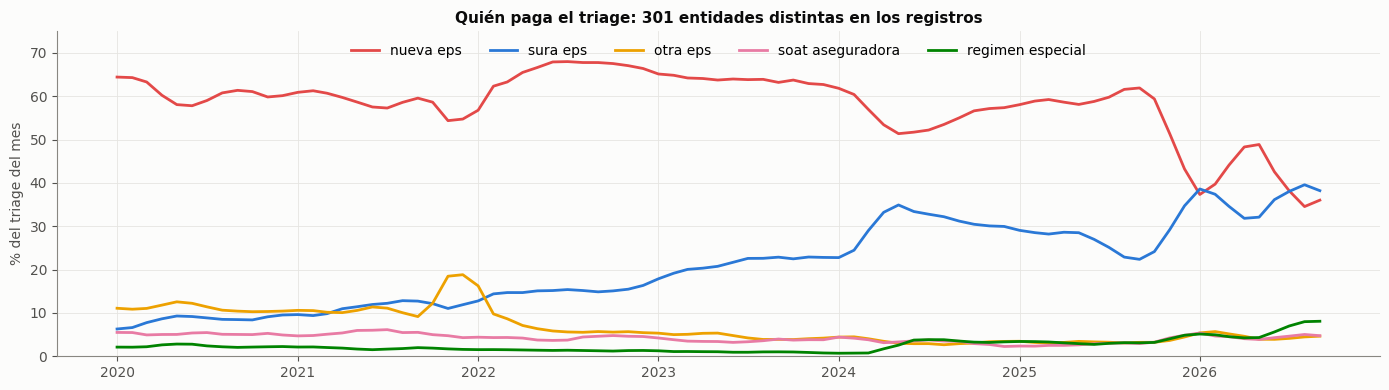

grupo,nueva_eps,sura_eps,otra_eps,regimen_especial,soat_aseguradora
mes,,,,,
2020,61.3,8.1,11.0,2.3,5.3
2021,57.6,11.3,13.2,1.8,5.2
2022,66.1,15.0,6.8,1.4,4.3
2023,63.9,21.4,4.6,1.0,3.7
2024,55.4,30.7,3.3,2.6,3.4
2025,58.0,27.0,3.3,3.3,3.0
2026,41.7,36.0,4.6,5.7,4.5


In [4]:
from extraccion.entidades import clasificar
te = pd.read_parquet(RAIZ / "salidas/triage_entidad.parquet", columns=["dia", "entidad", "n"])
te["mes"] = pd.to_datetime(te.dia).dt.to_period("M").dt.to_timestamp(); te = clasificar(te)
M = te.pivot_table(index="mes", columns="grupo", values="n", aggfunc="sum").fillna(0)
pesos = M.div(M.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots(figsize=(14, 4))
for gname, col in [("nueva_eps", ROJO), ("sura_eps", AZUL), ("otra_eps", AMARILLO), ("soat_aseguradora", MAGENTA), ("regimen_especial", VERDE)]:
    ax.plot(pesos.index, pesos[gname].rolling(3, center=True, min_periods=1).mean(), color=col, lw=2, label=gname.replace("_", " "))
ax.set_ylabel("% del triage del mes"); ax.legend(ncol=5, loc="upper center"); ax.set_ylim(0, 75)
ax.set_title(f"Quién paga el triage: {te.entidad.nunique()} entidades distintas en los registros"); plt.tight_layout(); plt.show()
anual = (M.groupby(M.index.year).sum().T / M.groupby(M.index.year).sum().sum(axis=1)).T * 100
anual[["nueva_eps", "sura_eps", "otra_eps", "regimen_especial", "soat_aseguradora"]].round(1)

**Lectura. El propietario tiene razón: el modelo miraba a una sola EPS.**

- **SURA EPS pasó del 8 % del triage (2020) al 36 % (2026).** Nueva EPS bajó del 61 % al 42 %.
- **Los pacientes no desaparecieron: se movieron de aseguradora.** Entre 2025 y 2026 el resto de aseguradoras subió de 84 a 100 triages al día mientras Nueva EPS caía.
- Hay **301 entidades distintas** en los registros, agrupadas en 12 grupos.
- **Lo que falta no son datos internos, sino el estado externo de cada EPS:** cuántos afiliados tiene en Manizales, si está intervenida, cuántas quejas recibe, cuánto le paga al hospital. Las cuatro cosas existen como fuentes públicas (sección 4.2).

## 3.2 Las enfermedades de Manizales: hay mucho más que IRA

In [5]:
e = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila_eventos.csv.gz")
e = e[(e.ambito == "manizales") & (e.variable == "casos_notificacion") & e.anio.between(2022, 2025)]
cen = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila_eventos_censo.csv").set_index("evento")["nombre"]
v = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila.csv.gz"); v = v[(v.ambito == "manizales") & v.anio.between(2022, 2025)]
filas = [{"evento": "995 consultas por IRA", "casos 2022-2025": v[(v.evento == 995) & (v.variable == "consultas_ira_total")].valor.sum()},
         {"evento": "998 EDA (diarrea)", "casos 2022-2025": v[(v.evento == 998) & (v.variable == "casos_eda_total")].valor.sum()}]
top = e.groupby("evento").valor.sum().sort_values(ascending=False).head(10)
filas += [{"evento": f"{k} {cen.get(k, '')}".strip(), "casos 2022-2025": val} for k, val in top.items()]
D = pd.DataFrame(filas); D["casos 2022-2025"] = D["casos 2022-2025"].astype(int)
D["¿entró al modelo?"] = ["sí (E2/E3)", "no: no hay 2026", "sí (E2)", "sí (E2)", "sí (E2)", "sí (E2)", "no", "no", "sí (E2)", "no", "no", "no"][:len(D)]
D

,evento,casos 2022-2025,¿entró al modelo?
0,995 consultas por IRA,248277,sí (E2/E3)
1,998 EDA (diarrea),82679,no: no hay 2026
2,300 AGRESIONES POR ANIMALES POTENCIALMENTE TRA...,5900,sí (E2)
3,875 VCM VIF VSX,5499,sí (E2)
4,356 INTENTO DE SUICIDIO,2812,sí (E2)
5,365 INTOXICACIONES (suma de 360-414),2237,sí (E2)
6,549 MORBILIDAD MATERNA EXTREMA,1854,no
7,370 INTOXICACION POR FARMACOS,1666,no
8,831 VARICELA INDIVIDUAL,963,sí (E2)
9,850 VIH/SIDA/MORTALIDAD POR SIDA,912,no


**Lectura.**

- **Por volumen, la salud pública de Manizales son dos grandes y varias medianas.** IRA (248.277 consultas en 2022-2025) y EDA (82.679 casos) son de otro orden de magnitud. Les siguen las agresiones por animales, la violencia de género, el intento de suicidio, las intoxicaciones, la morbilidad materna extrema y la varicela.
- **Al modelo entraron la IRA y 5 eventos**, pero:
  - **la EDA no**, porque no hay 2026 sin una foto de Power BI;
  - **lo materno-perinatal no**, y el hospital tiene un 12,6 % de triage obstétrico.
- **Las 5-6 familias con volumen para entrenar** son: respiratoria (IRA, IRAG), digestiva (EDA), violencias y agresiones (875, 300), salud mental e intoxicaciones (356, 365), materno-perinatal (549).
- **El dengue no aplica:** no hay transmisión en Manizales por la altitud.

## 3.3 El clima: qué hay y qué falta construir

El clima unificado tiene 69 columnas. Al modelo entraron **12 variables de nivel o anomalía**: temperatura
media, mínima y máxima, amplitud, humedad, lluvia de 7 y 30 días, radiación y su cambio, y viento. **Falta lo
que el propietario pide y lo que `CLAUDE.md` llama «la transición, no el nivel»:**

| Lo que falta | Cómo se construye | De dónde |
|---|---|---|
| **Cuántos días lleva sin llover** y la racha seca | días desde el último día con lluvia ≥ 1 mm (solo pluviómetro válido o acumulados) | `clima_unificado` |
| **Cuántos días lleva haciendo sol** | racha de días con radiación u horas de sol sobre lo normal del mes | `clima_unificado` + Open-Meteo |
| **Horas de sol y nubosidad** | `sunshine_duration`, `cloud_cover` | Open-Meteo (también en pronóstico desde 2024) |
| **Punto de rocío y humedad absoluta** | `dew_point_2m` | Open-Meteo, NASA POWER |
| **Cambio brusco** (seco → lluvioso, cálido → frío) | diferencia entre la última semana y las 3 anteriores, contra lo normal | derivado |
| **Extremos** | días con lluvia > p90 o temperatura < p10 en la última semana | derivado |
| **Lo que se sabrá al predecir** | el **pronóstico** del clima de los próximos días, no el observado | Open-Meteo Previous Runs (desde 2024) |

## 3.4 Fenómenos y catástrofes: cuántos hay de los que aprender

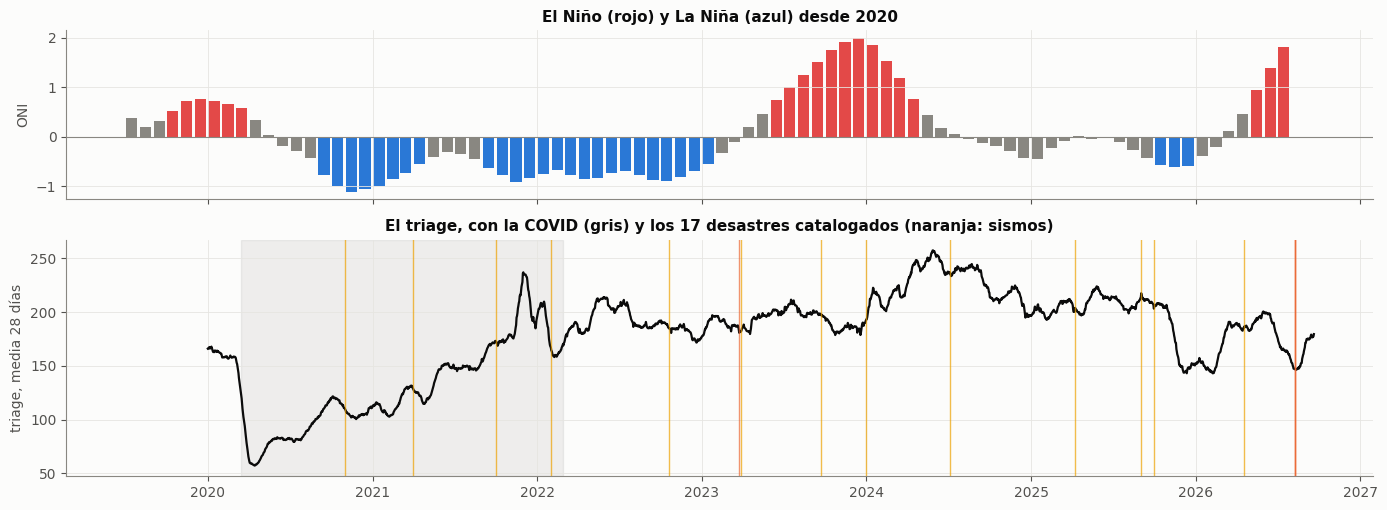

Episodios ENSO desde mediados de 2019:
            fase  meses
         neutral      3
         el_nino      6
         neutral      5
         la_nina      8
         neutral      4
         la_nina     17
         neutral      4
         el_nino     11
         neutral     24
el_nino_en_curso      3

Desastres catalogados 2020-2026: 17 ({'deslizamiento': 9, 'sismo': 4, 'actividad_volcanica': 1, 'vendaval': 1, 'incendio_forestal': 1, 'multiple': 1})


In [6]:
en = pd.read_csv(RAIZ / "calendarios/enso_oni.csv", parse_dates=["fecha"]); en = en[en.fecha >= "2019-07-01"]
pr.usar("e1"); y, _ = pr.cargar()
fig, axes = plt.subplots(2, 1, figsize=(14, 5.2), sharex=True, gridspec_kw={"height_ratios": [1, 1.4]})
axes[0].bar(en.fecha, en.oni, width=25, color=np.where(en.oni > 0.5, ROJO, np.where(en.oni < -0.5, AZUL, MUDO)))
axes[0].axhline(0, color=MUDO, lw=.8); axes[0].set_ylabel("ONI"); axes[0].set_title("El Niño (rojo) y La Niña (azul) desde 2020")
axes[1].plot(y.index, y.rolling(28, center=True, min_periods=14).mean(), color=TINTA, lw=1.6)
d = pd.read_csv(RAIZ / "calendarios/desastres_manizales_2020_2026.csv", parse_dates=["fecha_inicio"])
for _, r in d.iterrows(): axes[1].axvline(r.fecha_inicio, color=NARANJA if r.tipo_evento == "sismo" else AMARILLO, lw=1, alpha=.7)
axes[1].axvspan(pd.Timestamp("2020-03-15"), pd.Timestamp("2022-02-28"), color=MUDO, alpha=.12)
axes[1].set_ylabel("triage, media 28 días"); axes[1].set_title("El triage, con la COVID (gris) y los 17 desastres catalogados (naranja: sismos)")
plt.tight_layout(); plt.show()
fase = en.set_index("fecha").fase
ep = fase.groupby((fase != fase.shift()).cumsum()).agg(["first", "size"]).rename(columns={"first": "fase", "size": "meses"})
print("Episodios ENSO desde mediados de 2019:"); print(ep.to_string(index=False))
print(f"\nDesastres catalogados 2020-2026: {len(d)} ({d.tipo_evento.value_counts().to_dict()})")

**Lectura. Aquí está el límite más duro, y no es de código sino de muestra.**

- Desde 2020 hay **unos 4 episodios ENSO**: La Niña 2020-21, La Niña 2021-23, El Niño 2023-24 y el El Niño fuerte que está en curso (JAS 2026 = +2,16).
- Hay **1 COVID** y **17 desastres catalogados**, la mayoría deslizamientos locales.
- **Con 4 ejemplos, un modelo no aprende el efecto de El Niño: memoriza lo que pasó en esos 4.** Eso es exactamente el sobreajuste.
- **Lo que sí se puede hacer:**
  - marcar los fenómenos como **estados que duran meses** (régimen El Niño, La Niña, neutral; EPS intervenida; alerta hospitalaria);
  - usar **la historia larga del entorno** (SIVIGILA desde 2007, clima desde 1981) para aprender cómo afecta cada fenómeno a la **ciudad**, y trasladar al hospital solo ese efecto ya aprendido.

---
# 4. Las fuentes que se pueden sumar

Inventario verificado en la web el 2026-10-05, sumado al del repositorio (`calendarios/docs/FUENTES_EXTERNAS.md`,
`FUENTES_VIGILANCIA.md`, `INVENTARIO.md`). La columna que más importa es **«¿se tiene al predecir?»**: un dato
que llega 8 meses tarde sirve para entrenar, no para pronosticar.

## 4.1 Salud (SIVIGILA y otras)

| Fuente | Qué da | Granularidad | ¿Se tiene al predecir? | Estado |
|---|---|---|---|---|
| **Microdatos SIVIGILA** (portalsivigila.ins.gov.co/Microdatos) | todos los eventos, caso a caso; IRA y EDA colectivas | semana × municipio, 2007-2025 | no: ~8 meses de retraso | en el repo (entrenar) |
| **Power BI del INS** (tableros 006 rutinaria y 995) | evento × semana × municipio; IRA con denominador | semana, Manizales | **sí: ~7 días** | en el repo, una sola foto. **Falta la tarea semanal que la congele** |
| BES del INS | tablero departamental | semana, Caldas | sí: ~6 días | PDF |
| Boletines DTSC y Secretaría de Salud de Manizales | IRA, EDA y varicela por edad | semana o mes | tarde, en bloque | PDF |
| **Cubos SISPRO/RIPS** | **consultas, urgencias y hospitalización por diagnóstico CIE-10 y municipio** | mensual | no (meses) | **piden usuario de MinSalud** |
| **Diagnósticos del propio hospital** (cuaderno 10) | respiratorio, infeccioso, trauma, embarazo, urinario… | diario, desde 2020 | **sí** | en el repo, `perfil_dx_diario` (local) |

## 4.2 Estado de **todas** las EPS

| Fuente | Qué da | Granularidad | ¿Se tiene al predecir? |
|---|---|---|---|
| **MinSalud, cifras de afiliación** | afiliados por EPS × municipio × régimen | mensual, desde 2016 (Tableau) | sí: 1 mes |
| **Supersalud, medidas especiales**, resoluciones y FENIX | intervenciones, vigilancia especial, liquidaciones, con fecha | por evento | sí |
| **Supersalud, PQRD** | quejas por EPS y motivo, tasa por cada 10.000 afiliados (barreras de acceso) | mensual, desde 2017 | sí: ~5 semanas |
| **ADRES, giro directo** | cuánto paga cada EPS a cada IPS (incluido el SES) | mensual, desde 2020 | por verificar |
| BDUA en datos.gov.co | foto de afiliados por EPS y municipio | foto mensual, **sin histórico** | sí. **Hay que guardarla cada mes** |
| **El triage del propio hospital por asegurador** | peso y cambio de cada EPS en la demanda | diario, desde 2020 | **sí** |

**Cómo monitorear las EPS de forma continua:** una tarea mensual que descargue el zip de afiliación de
MinSalud, la foto de la BDUA, el Excel de medidas y el de PQRD. Más una revisión de resoluciones nuevas de
la Supersalud y de noticias de la Alcaldía (ya hay una API en el repo). No se encontró RSS ni API de la
Supersalud.

## 4.3 Clima, fenómenos y otras señales

| Fuente | Qué da | ¿Se tiene al predecir? |
|---|---|---|
| **Open-Meteo Previous Runs** | **pronóstico** a 1-7 días: lluvia, temperatura, humedad, **horas de sol**, nubosidad | **sí**, desde ~2024 |
| Open-Meteo Historical Forecast / ERA5, NASA POWER, IDEAM | clima observado o de reanálisis | observado: hasta el día anterior |
| **NOAA ONI** | El Niño / La Niña (JAS 2026 = +2,16: El Niño fuerte) | sí: ~1 mes |
| USGS | sismos (27 de M ≥ 3 a menos de 100 km desde 2020) | sí: minutos |
| UNGRD | emergencias por municipio | no: ≥ 9 meses; muy ralo |
| Open-Meteo Air Quality, SISAIRE | PM2.5 y PM10 (con pronóstico desde 2022) | sí |
| Google Trends (API alfa) | búsquedas de síntomas | hay que pedir acceso |

---
# 5. ¿Cuánto se le puede dar al modelo antes de sobreajustarlo?

**El límite no lo pone la cantidad de variables, sino la cantidad de *ejemplos independientes* de cada
fenómeno.**

- **Días.** De 2022 a 2025 hay ~1.400 días, pero los días seguidos se parecen (autocorrelación de 0,35).
  Equivalen a unos **670 días independientes**. Una regla prudente es pedir al menos 10-20 ejemplos
  independientes por cada parámetro que se estima. Para efectos diarios (clima de la semana, eventos),
  eso da **del orden de 30 a 60 parámetros** como techo.
- **Fenómenos raros.** Para El Niño, la COVID o un terremoto, el ejemplo no es un día sino **un
  episodio**. Desde 2020 hay unos **4 episodios ENSO**, **1 COVID** y **un puñado de sismos**. Con 4
  ejemplos no se aprende un efecto: el modelo memoriza qué pasó en esos 4. Eso es exactamente el
  sobreajuste que preocupa al propietario.
- **Lo que ya se midió en este proyecto:** al pasar de 28 a 36 entradas (E3) y a 77 (E2), la regresión y
  LightGBM **empeoraron** en 2026.

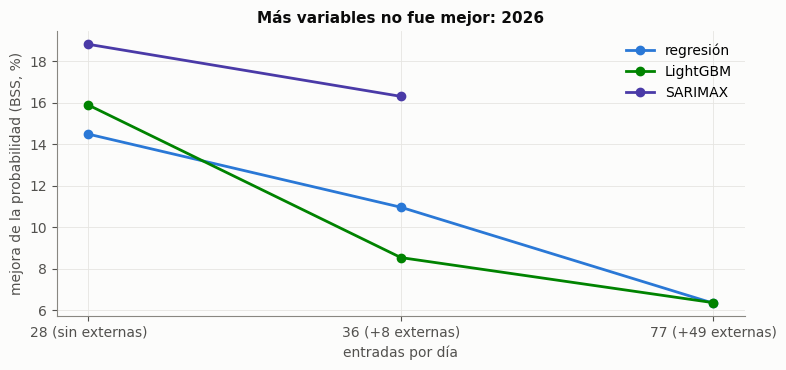

BSS sube %                   acierta %                 
modelo            glm_binneg lightgbm sarimax glm_binneg lightgbm sarimax
entradas                                                                 
28 (sin externas)       14.5     15.9    18.8       65.0     67.8    66.8
36 (+8 externas)        11.0      8.5    16.3       62.5     64.9    65.0
77 (+49 externas)        6.3      6.4     NaN       59.9     62.6     NaN

In [7]:
filas = []
for exp, n in [("e1", "28 (sin externas)"), ("e3", "36 (+8 externas)"), ("e2", "77 (+49 externas)")]:
    for m in ["glm_binneg", "lightgbm", "sarimax"]:
        f = pr.SALIDA / exp / f"{m}.parquet"
        if f.exists():
            P, _ = pr.leer([m], exp=exp); P = P[P.origen >= "2025-12-31"]
            t = tabla(P).iloc[0]; filas.append({"entradas": n, "modelo": m, "BSS sube %": t["BSS sube %"], "acierta %": t["acierta sube/baja %"]})
F = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(8, 3.8))
for m, col in [("glm_binneg", AZUL), ("lightgbm", VERDE), ("sarimax", VIOLETA)]:
    g = F[F.modelo == m]; ax.plot(g.entradas, g["BSS sube %"], "-o", color=col, lw=2, label={"glm_binneg": "regresión", "lightgbm": "LightGBM", "sarimax": "SARIMAX"}[m])
ax.set_ylabel("mejora de la probabilidad (BSS, %)"); ax.set_xlabel("entradas por día"); ax.legend()
ax.set_title("Más variables no fue mejor: 2026"); plt.tight_layout(); plt.show()
F.pivot_table(index="entradas", columns="modelo", values=["acierta %", "BSS sube %"]).round(1)

**Cómo darle más contexto sin sobreajustar:**

1. **Índices por familia en vez de variables sueltas.** Por ejemplo, un «índice de presión respiratoria» que
   resuma IRA total, IRA 0-4, IRAG y consultas. O un «estado del clima» que resuma temperatura, humedad, sol
   y lluvia. Al modelo entra una cifra por familia, y el contexto completo sigue representado.
2. **Regímenes, no episodios.** El Niño, La Niña, «EPS en crisis» o «temporada festiva» entran como **estados**
   que se repiten, no como fechas únicas. Un estado con muchos días sí se puede aprender.
3. **Modelos que se frenan solos.** Regularización (Ridge/Lasso), árboles poco profundos, mínimo de ejemplos
   por hoja. La rejilla de la sección 6 eligió árboles de profundidad 2-3: los datos piden simplicidad.
4. **Agregar familias de una en una**, y quedarse solo con las que mejoran en un año de validación distinto
   del de prueba.
5. **Llevar cada contexto a la serie donde actúa.** El clima y la IRA mueven lo **respiratorio** del
   hospital (+10-14 %, cuaderno 13) y se diluyen en el total. Un modelo jerárquico **por tipo de
   consulta** (respiratorio, infeccioso, trauma, embarazo, otros), cada uno con su contexto, suma al final
   el total. Es la arquitectura escalable que pide el propietario.

---
# 6. El método de rejilla, en simple

**La idea.** Un modelo tiene perillas que hay que fijar antes de entrenarlo: cuántos árboles, qué tan
profundos, qué tan rápido aprende. Se llaman **hiperparámetros**. El método de rejilla (*grid search*):
1. arma una **lista de valores** para cada perilla, por ejemplo profundidad 2, 3 o 4, y 200 o 500 árboles;
2. prueba **todas las combinaciones**: 3 × 2 = 6 modelos;
3. mide cada uno con datos que no usó para entrenar, y **se queda con el que menos se equivoca**.

Es como probar recetas cambiando la temperatura del horno y el tiempo, y quedarse con la que sale mejor.

**¿Se puede usar aquí? Sí, y ya se usó.** En el cuaderno 15 se afinaron XGBoost, GradientBoosting y
LightGBM con una rejilla sobre 2024. Esta es la rejilla real de XGBoost (error medio del log en 2024; menos es
mejor):

In [8]:
E = json.loads((pr.SALIDA / "e1" / "_afinado_xgboost_etapas.json").read_text(encoding="utf-8"))
R = pd.DataFrame(E["rejilla"]).sort_values("mae_log"); R["error medio %"] = (np.exp(R.mae_log) - 1) * 100
print("elegida:", E["elegida"]); R.round(4)

elegida: {'max_depth': 2, 'n_estimators': 500, 'learning_rate': 0.1}


,max_depth,n_estimators,learning_rate,mae_log,error medio %
0,2,500,0.10,0.0975,10.2459
1,3,500,0.10,0.1021,10.7440
2,3,500,0.03,0.1025,10.7960
3,4,500,0.03,0.1035,10.9072
4,3,200,0.10,0.1037,10.9223
5,2,200,0.10,0.1039,10.9474
6,4,500,0.10,0.1053,11.1020
7,4,200,0.10,0.1064,11.2259
8,2,500,0.03,0.1107,11.7037
9,4,200,0.03,0.1130,11.9640


**Las tres reglas para que la rejilla no engañe:**
1. **Se afina en un periodo y se prueba en otro.** Se afinó con 2024, se calibró con 2025 y se probó en
   2026. Si se afina mirando la prueba, la rejilla «encuentra» la combinación que acierta por suerte.
2. **Pocas perillas y pocos valores.** Con 12 combinaciones el riesgo es bajo. Con miles, alguna gana por
   azar. Para rejillas grandes es mejor la **búsqueda aleatoria** o la **bayesiana** (por ejemplo, Optuna).
3. **Validación de origen rodante dentro del periodo de afinado**, nunca un corte al azar.

**Lo que enseñó en este proyecto:** la rejilla eligió árboles **poco profundos** (2-3 niveles). Lo mejor
de 2024 no fue lo mejor de 2026, porque 2026 fue otro régimen (Nueva EPS). Afinar ayuda, pero no
reemplaza tener las variables correctas.

---
# 7. Propuesta: un entrenamiento holístico y escalable

| Capa | Qué entra | Cómo, sin sobreajustar |
|---|---|---|
| **Red de salud** | **todas** las EPS: afiliados mensuales (MinSalud), medidas e intervenciones (Supersalud), quejas (PQRD), giros (ADRES), peso de cada EPS en el triage | un **índice de estrés de la red** + el estado de las 3-4 EPS grandes (Nueva EPS, SURA, Salud Total, Sanitas) |
| **Calendario y vida social** | festivos, puentes, quincena, vacaciones y horario escolar, Feria, fiestas, días especiales | como hoy |
| **Clima completo** | nivel + **rachas** (días sin lluvia, días de sol) + **transiciones** + horas de sol y nubosidad + **pronóstico** | índices de «estado del clima» y de «cambio brusco», con rezagos de 1-3 semanas |
| **Salud pública** | las 5-6 familias con volumen en Manizales: **IRA, EDA, violencias y agresiones, salud mental e intoxicaciones, materno-perinatal** | un índice por familia, con rezago de 1 semana (Power BI) |
| **Regímenes y fenómenos** | El Niño / La Niña, COVID, sismo fuerte, alerta hospitalaria, EPS intervenida | **estados** que se repiten, no fechas sueltas |
| **Estructura** | **jerárquico por tipo de consulta**: respiratorio, infeccioso, trauma, embarazo, resto | cada parte con su contexto; el total es la suma |

**Cómo se prueba sin «darle las respuestas»:**
1. **Afinar** con 2020-2024.
2. **Elegir** el diseño con 2025, y solo con 2025.
3. **Probar una sola vez** en 2026, sin cambiar nada después.
4. **Prueba prospectiva:** congelar el modelo y compararlo con octubre-diciembre de 2026, que hoy nadie
   conoce. Es la única prueba que no se puede discutir.

## Resumen

**Lo que hay hoy.** La combinación **SARIMAX + LightGBM** es la mejor forma encontrada de predecir con calendario e historia.

- Es la mejor en dos años distintos.
- En 2025, el año con el que no se eligió nada, acierta ~60 % y su rango es honesto (78 %).
- **En 2026 luce mejor (69 %) porque ese año favoreció a los modelos que siguen el nivel.** Ese número no se debe prometer.

**Las preocupaciones del propietario, medidas:**

| Preocupación | Veredicto | Dato |
|---|---|---|
| Solo se mide Nueva EPS | **tiene razón** | SURA pasó de 8 % a 36 % del triage; falta el estado externo de todas |
| Al clima le falta contexto | **tiene razón** | entraron 12 niveles; faltan rachas, transiciones, horas de sol y pronóstico |
| Solo IRA | **en parte** | entraron IRA y 5 eventos; faltan EDA y lo materno-perinatal |
| No se marcaron los fenómenos | **en parte** | el ENSO entró como número, no como régimen; con 4 episodios no se puede aprender suelto |
| Se le dieron las respuestas de 2026 | **en parte** | no hubo fuga, pero elegir entre 20 diseños con 2026 infló el número: 69 % en 2026, 60 % en 2025 |

**Lo que se propone** (sección 7):

1. Panel externo de **todas las EPS**.
2. **Clima completo con rachas, transiciones y pronóstico.**
3. **Las 5-6 familias de enfermedades** como índices.
4. **Regímenes** en lugar de fechas sueltas.
5. **Un modelo jerárquico por tipo de consulta**, donde cada contexto actúa en su parte.
6. **Afinar en 2020-2024, elegir con 2025, probar una sola vez en 2026, y la prueba prospectiva.**

**El límite que no se puede saltar:** unos 670 días independientes. Eso deja espacio para **decenas** de parámetros, no centenares, y casi ninguno para fenómenos que han pasado 4 veces. La salida es **resumir por familias y por regímenes**, no sumar variables sueltas.